# Notebook 03 — LSTM Baseline: Training & Evaluation

**Model:** Stacked LSTM (2 layers, hidden=128, dropout=0.2)


In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from src.utils.config import DATA_PROC, OUT_MODELS, OUT_FIGURES
from src.models.lstm import LSTMModel
from src.utils.trainer import train, load_splits
from src.evaluation.metrics import all_metrics
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi':120,'figure.facecolor':'white'})
SUBSET='FD001'
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE} | PyTorch: {torch.__version__}')

Device: cpu | PyTorch: 2.12.1+cpu


## 1 · Verify data

In [2]:
proc=DATA_PROC/SUBSET
for name in ['X_train','y_train','X_val','y_val','X_test','y_test']:
    p=proc/f'{name}.npy'
    if p.exists():
        a=np.load(p)
        print(f'  {name:12s}  {str(a.shape):20s}')
    else:
        print(f'  MISSING: {p}')

  X_train       (15332, 30, 14)     
  y_train       (15332,)            
  X_val         (2399, 30, 14)      
  y_val         (2399,)             
  X_test        (100, 30, 14)       
  y_test        (100,)              


## 2 · Model architecture

In [ ]:
model=LSTMModel()
print(model)
print(f'\nParameters: {model.count_parameters():,}')
dummy=torch.randn(4,30,14)
with torch.no_grad():
    out=model(dummy)
print(f'Forward pass: {dummy.shape} -> {out.shape} ')

LSTMModel(
  (lstm): LSTM(14, 128, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Parameters: 214,401
Forward pass: torch.Size([4, 30, 14]) → torch.Size([4]) ✓


## 3 · Train

In [4]:
results=train(model_name='lstm',subset=SUBSET)
print('Training complete.')


  Model   : LSTM
  Subset  : FD001
  Device  : cpu
  Parameters : 214,401
  Train batches : 60  |  Val batches : 10
  Ep   1/100  train_mse=6603.8161  val_rmse=62.8102  lr=1.00e-03  [9s]
  Ep   5/100  train_mse=364.3854  val_rmse=16.0627  lr=1.00e-03  [63s]
  Ep  10/100  train_mse=259.8333  val_rmse=13.7271  lr=1.00e-03  [152s]
  Ep  15/100  train_mse=233.8928  val_rmse=14.7122  lr=1.00e-03  [201s]
  Ep  20/100  train_mse=217.8950  val_rmse=13.4531  lr=1.00e-03  [249s]
  Ep  25/100  train_mse=213.3479  val_rmse=13.8872  lr=1.00e-03  [312s]
  Ep  30/100  train_mse=213.3206  val_rmse=12.9778  lr=1.00e-03  [411s]
  Ep  35/100  train_mse=192.5898  val_rmse=13.6129  lr=5.00e-04  [456s]
  Ep  40/100  train_mse=194.6615  val_rmse=12.8708  lr=5.00e-04  [560s]
  Ep  45/100  train_mse=185.2539  val_rmse=13.7568  lr=2.50e-04  [679s]
  Ep  50/100  train_mse=185.6237  val_rmse=13.2704  lr=2.50e-04  [802s]

  Early stopping at epoch 51 (no improvement for 15 epochs)

  ── Test Results (LSTM, FD001)

## 4 · Training curves

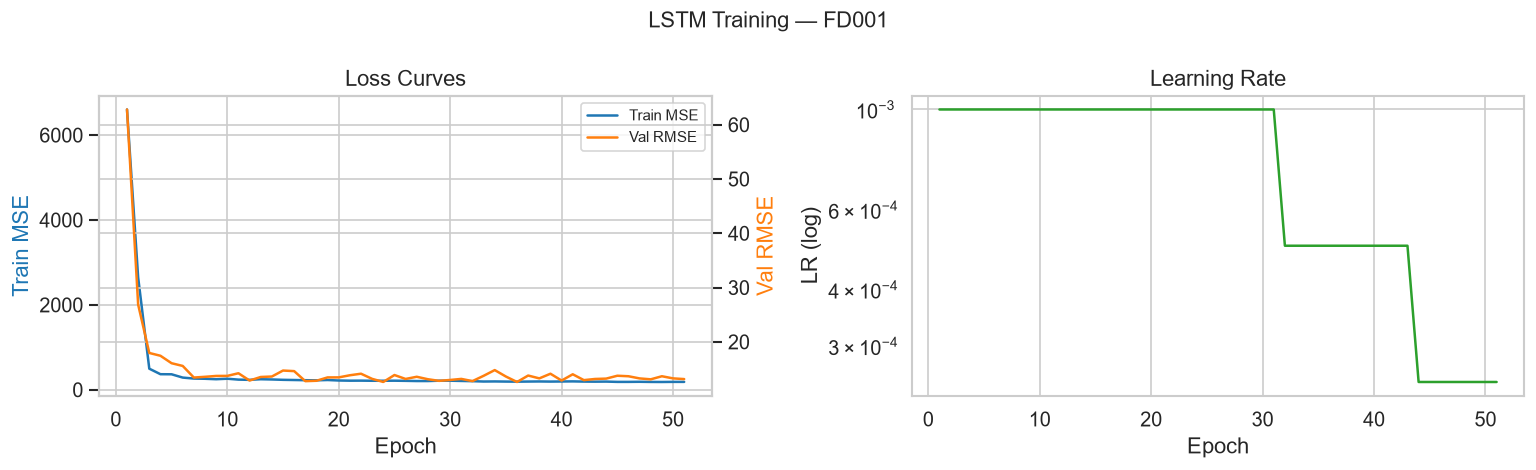

Best val RMSE: 12.6056  |  Epochs run: 51


In [5]:
log=results['log']
epochs=[r['epoch'] for r in log]
train_mse=[r['train_mse'] for r in log]
val_rmse=[r['val_rmse'] for r in log]
lrs=[r['lr'] for r in log]
fig,axes=plt.subplots(1,2,figsize=(13,4))
ax=axes[0];ax2=ax.twinx()
ax.plot(epochs,train_mse,color='#1f77b4',lw=1.5,label='Train MSE')
ax2.plot(epochs,val_rmse,color='#ff7f0e',lw=1.5,label='Val RMSE')
ax.set_xlabel('Epoch');ax.set_ylabel('Train MSE',color='#1f77b4')
ax2.set_ylabel('Val RMSE',color='#ff7f0e');ax.set_title('Loss Curves')
l1,lb1=ax.get_legend_handles_labels();l2,lb2=ax2.get_legend_handles_labels()
ax.legend(l1+l2,lb1+lb2,fontsize=9)
axes[1].semilogy(epochs,lrs,color='#2ca02c',lw=1.5)
axes[1].set_xlabel('Epoch');axes[1].set_ylabel('LR (log)');axes[1].set_title('Learning Rate')
fig.suptitle(f'LSTM Training — {SUBSET}',fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES/f'lstm_{SUBSET}_training_curves.png',bbox_inches='tight')
plt.show()
print(f'Best val RMSE: {results["best_val_rmse"]:.4f}  |  Epochs run: {results["epochs_run"]}')

## 5 · Test metrics

In [6]:
m=results['test']
print(f'RMSE={m["RMSE"]:.3f}  MAE={m["MAE"]:.3f}  R2={m["R2"]:.4f}  NASA={m["NASA_Score"]:.1f}')

RMSE=12.876  MAE=9.824  R2=0.8968  NASA=232.8


## 6 · Predicted vs actual

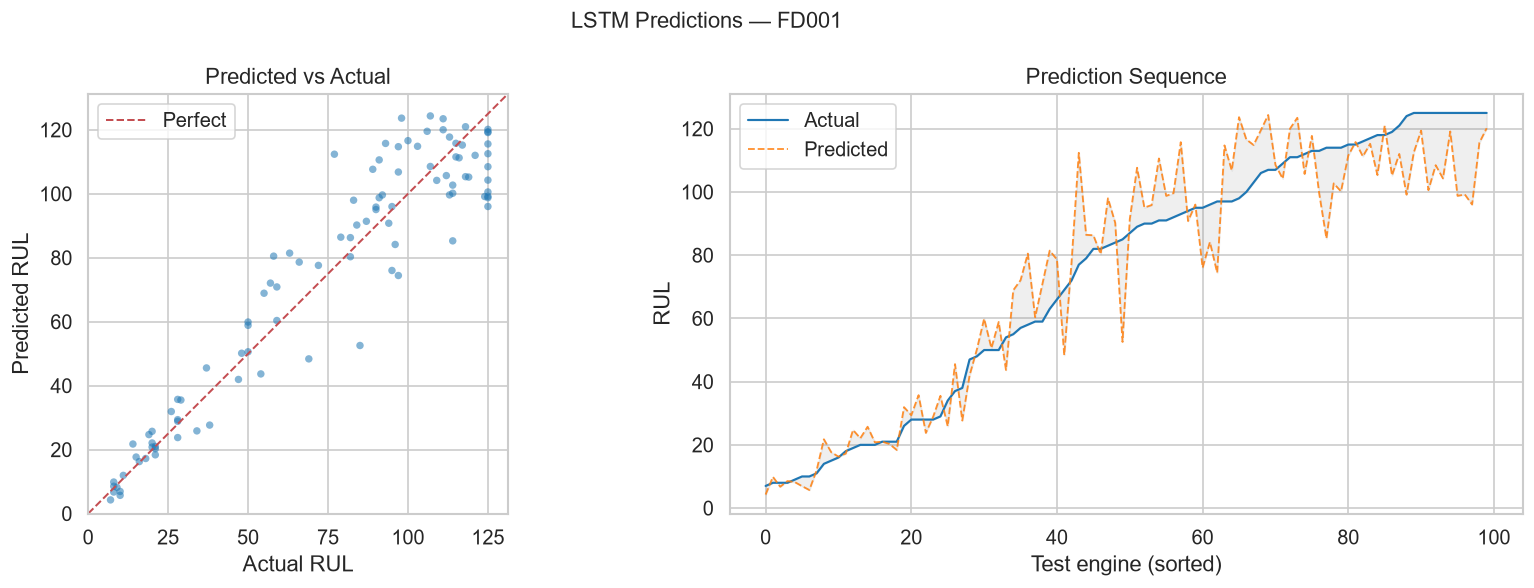

In [7]:
_,_,te_loader,y_test=load_splits(SUBSET,DEVICE)
best=LSTMModel().to(DEVICE)
best.load_state_dict(torch.load(OUT_MODELS/f'lstm_{SUBSET}_best.pt',map_location=DEVICE,weights_only=True))
best.eval()
preds=[]
with torch.no_grad():
    for X_b,_ in te_loader:
        preds.append(best(X_b.to(DEVICE)).cpu().numpy())
preds=np.concatenate(preds)
fig,axes=plt.subplots(1,2,figsize=(14,5))
ax=axes[0]
ax.scatter(y_test,preds,alpha=0.55,s=20,color='#1f77b4',edgecolors='none')
lim=[0,max(y_test.max(),preds.max())*1.05]
ax.plot(lim,lim,'r--',lw=1.2,label='Perfect')
ax.set_xlim(lim);ax.set_ylim(lim)
ax.set_xlabel('Actual RUL');ax.set_ylabel('Predicted RUL')
ax.set_title('Predicted vs Actual');ax.legend();ax.set_aspect('equal')
idx=np.argsort(y_test)
axes[1].plot(y_test[idx],label='Actual',color='#1f77b4',lw=1.3)
axes[1].plot(preds[idx],label='Predicted',color='#ff7f0e',lw=1.1,ls='--',alpha=0.85)
axes[1].fill_between(range(len(y_test)),y_test[idx],preds[idx],alpha=0.12,color='grey')
axes[1].set_xlabel('Test engine (sorted)');axes[1].set_ylabel('RUL');axes[1].legend()
axes[1].set_title('Prediction Sequence')
fig.suptitle(f'LSTM Predictions — {SUBSET}',fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES/f'lstm_{SUBSET}_predictions.png',bbox_inches='tight')
plt.show()

## 7 · Error analysis

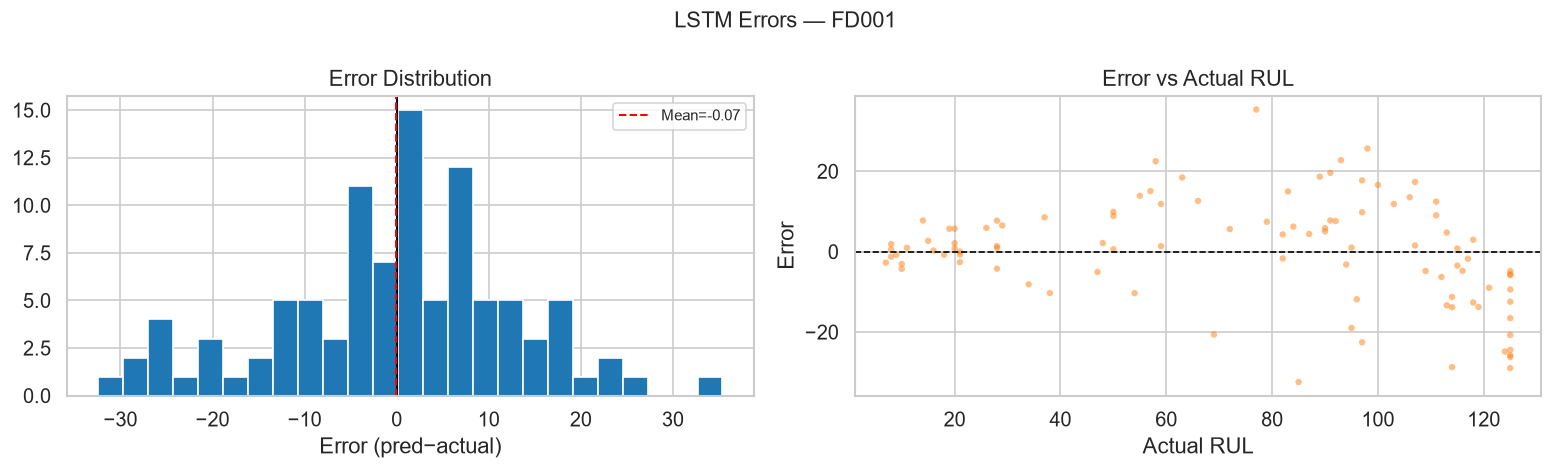

Bias: -0.074  |  Within±10: 61.0%  |  Within±20: 86.0%
Early (risky): 56.0%  |  Late (safe): 44.0%


In [8]:
errors=preds-y_test
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].hist(errors,bins=25,color='#1f77b4',edgecolor='white')
axes[0].axvline(0,color='black',lw=1.2)
axes[0].axvline(errors.mean(),color='red',lw=1.2,ls='--',label=f'Mean={errors.mean():.2f}')
axes[0].set_xlabel('Error (pred−actual)');axes[0].set_title('Error Distribution');axes[0].legend(fontsize=9)
axes[1].scatter(y_test,errors,alpha=0.5,s=15,color='#ff7f0e',edgecolors='none')
axes[1].axhline(0,color='black',ls='--',lw=1)
axes[1].set_xlabel('Actual RUL');axes[1].set_ylabel('Error');axes[1].set_title('Error vs Actual RUL')
fig.suptitle(f'LSTM Errors — {SUBSET}',fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES/f'lstm_{SUBSET}_errors.png',bbox_inches='tight')
plt.show()
print(f'Bias: {errors.mean():.3f}  |  Within±10: {(np.abs(errors)<=10).mean()*100:.1f}%  |  Within±20: {(np.abs(errors)<=20).mean()*100:.1f}%')
print(f'Early (risky): {(errors>0).mean()*100:.1f}%  |  Late (safe): {(errors<0).mean()*100:.1f}%')

## 8 · Baseline comparison

In [12]:
m=results['test']
print(f"""

  LSTM BASELINE — {SUBSET}                        

  RMSE       : {m['RMSE']:>8.3f} cycles           
  MAE        : {m['MAE']:>8.3f} cycles            
  R2         : {m['R2']:>8.4f}                    
  NASA Score : {m['NASA_Score']:>10.1f}           

  PUBLISHED FD001 RMSE BASELINES                  
  LSTM  (Zheng et al., 2017)  : ~16.1             
  CNN   (Babu et al., 2016)   : ~18.5             
  Transformer (Fan, 2020)     : ~13.2             
  """)



  LSTM BASELINE — FD001                        

  RMSE       :   12.876 cycles           
  MAE        :    9.824 cycles            
  R2         :   0.8968                    
  NASA Score :      232.8           

  PUBLISHED FD001 RMSE BASELINES                  
  LSTM  (Zheng et al., 2017)  : ~16.1             
  CNN   (Babu et al., 2016)   : ~18.5             
  Transformer (Fan, 2020)     : ~13.2             
  
